# Sequential control and memory: method in practice

**Level:** 2  
**Prerequisites:** Sequential control and memory level 1  
**Reading time:** 25 minutes

**Question:** What happens when the released sequential policies act on the same cancellation state and seed?


## Objectives

For level 2 of long-job cancellation on C07, Trace decisions across the changing C07 process state. For level 2 of long-job cancellation on C07, The task is not one classification: For level 2 of long-job cancellation on C07, waiting, observing job completion, honoring cancellation and checking the final postcondition form a time-ordered control problem with measurable effects.


## Setup

The versions below are pinned in `notebooks/requirements.txt` and are also recorded in this notebook's metadata.

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```


In [1]:
# Import the released policy API and the pinned plotting/runtime dependencies.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")


reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Data
For level 2 of long-job cancellation on C07, The notebook reads committed product artifacts. For level 2 of long-job cancellation on C07, Owner: For level 2 of long-job cancellation on C07, Neuraxis. For level 2 of long-job cancellation on C07, Repository: For level 2 of long-job cancellation on C07, https://github.com/fsantibanezleal/CAOS_Neuraxis. License: For level 2 of long-job cancellation on C07, Apache-2.0. For level 2 of long-job cancellation on C07, The JSON is a first-party, frozen experiment artifact; For level 2 of long-job cancellation on C07, no external benchmark data are redistributed in this notebook.

For level 2 of long-job cancellation on C07, This notebook reads `data/derived/index.json` and the listed trace artifacts. For level 2 of long-job cancellation on C07, The method run uses an isolated Reflexmesh case workspace. For level 2 of long-job cancellation on C07, For learned methods, fetch the exact public release assets with `python -m reflexmesh.cli fetch-models --destination models/checkpoints --version v0.01.000`, then set `NEURAXIS_CHECKPOINTS` to that folder. For level 2 of long-job cancellation on C07, The release manifest verifies asset hashes. For level 2 of long-job cancellation on C07, Planner methods M09/M10 are read from frozen traces unless `NEURAXIS_NOTEBOOK_MODEL` explicitly names a configured local Ollama model.

For level 2 of long-job cancellation on C07, Artifacts for this lesson:

- `data/derived/index.json`
- `data/derived/benchmark-adequacy.json`
- `data/derived/episodes/M05-C07-nominal-40000.json`
- `data/derived/episodes/M06-C07-nominal-40000.json`
- `data/derived/episodes/M07-C07-nominal-40000.json`
- `data/derived/episodes/M08-C07-nominal-40000.json`


## Method

For level 2 of long-job cancellation on C07, The action sequence matters because every operation changes the next observation. For level 2 of long-job cancellation on C07, Recurrent policies can retain an episode-local hidden state, while PPO learns from discounted transitions and the lookahead method predicts bounded consequences. For level 2 of long-job cancellation on C07, Those mechanisms make different assumptions about memory, rewards and model error. For level 2 of long-job cancellation on C07, Cancellation adds a safety-critical termination condition: For level 2 of long-job cancellation on C07, a policy that eventually reaches a successful postcondition after ignoring a cancellation request is not equivalent to one that obeys the request. For level 2 of long-job cancellation on C07, Inspect the recorded event order, the cancellation state and the terminal oracle separately. For level 2 of long-job cancellation on C07, The C07 family is especially diagnostic because all forty M12 core failures cluster there; For level 2 of long-job cancellation on C07, a pooled success rate would hide that pattern. For level 2 of long-job cancellation on C07, At level 2, for long-job cancellation on C07, C07 is a temporal control problem. For level 2 of long-job cancellation on C07, At level 2, for long-job cancellation on C07, cancellation safety requires that the requested stop takes effect, while liveness requires that the controller eventually observes a terminal job state. For level 2 of long-job cancellation on C07, At level 2, for long-job cancellation on C07, A policy must react to transitions across wait, poll and cancel actions. For level 2 of long-job cancellation on C07, At level 2, for long-job cancellation on C07, scoring a single snapshot discards the event order that determines whether a long-running process is still safe to continue. For level 2 of long-job cancellation on C07, At level 2, for long-job cancellation on C07, The independent postcondition should inspect the final process state and recorded effects, because a cancel request alone is not proof that execution stopped or that a later retry did not restart it. For level 2 of long-job cancellation on C07, At level 2, for long-job cancellation on C07, Matched variants can probe cancellation before launch, during execution and near completion, separating controller responsiveness from environment timing and exposing race-sensitive failures. For level 2 of long-job cancellation on C07, At level 2, for long-job cancellation on C07, A recurrent model is justified only if its memory changes decisions under partial observation and improves held-out completion enough to pay for its additional latency and state complexity. For level 2 of long-job cancellation on C07, At level 2, for long-job cancellation on C07, For this level, inspect every transition that follows a cancel request and distinguish the controller's command from the environment's observed terminal state. For level 2 of long-job cancellation on C07, At level 2, for long-job cancellation on C07, A useful extension shifts the cancellation event across the job timeline while holding task content constant, then measures completion, elapsed time and unintended continuation.


### long-job cancellation · level 2 — Verify the audit and each trace's bytes before interpreting outcomes.


In [2]:
# Load and hash-check the selected first-party traces; never edit the canonical artifacts.
ROOT = Path("../../../").resolve()
index_path = ROOT / "data/derived/index.json"
index_bytes = index_path.read_bytes()
index = json.loads(index_bytes)
audit = json.loads((ROOT / "data/derived/benchmark-adequacy.json").read_text(encoding="utf-8"))
assert hashlib.sha256(index_bytes).hexdigest() == audit["index_sha256"]
selected_methods = ["M05", "M06", "M07", "M08"]
trace_methods = ["M05", "M06", "M07", "M08"]
sample_case = "C07"
seed = 40000
records = {}
for method_id in trace_methods:
    row = next(
        record
        for record in index["episodes"]
        if record["method_id"] == method_id
        and record["case_id"] == sample_case
        and record["variant"] == "nominal"
        and record["seed"] == seed
    )
    trace_path = ROOT / "data/derived" / row["path"]
    trace_bytes = trace_path.read_bytes()
    assert hashlib.sha256(trace_bytes).hexdigest() == row["sha256"]
    records[method_id] = json.loads(trace_bytes)
checkpoint_dir = Path(os.environ.get("NEURAXIS_CHECKPOINTS", str(ROOT / "models/checkpoints")))
planner_model = os.environ.get("NEURAXIS_NOTEBOOK_MODEL")
planner = OllamaPlanner(planner_model) if planner_model else None
print("Hash-verified trace records:", len(records))


Hash-verified trace records: 4


### long-job cancellation · level 2 — Execute the released policies and compare the run


### long-job cancellation · level 2 — Compare the full sequence, not only the first action


### long-job cancellation · L2 — Build the first executable policy

In level 2, construct policy M05 for long-job cancellation with the public factory and keep its observation contract unchanged before sampling C07.


In [3]:
# Construct the first released policy through the public factory.
primary_id = "M05"
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Primary policy:", primary_id)


Primary policy: M05


### long-job cancellation · L2 — Execute the primary method on the named case

At level 2, the long-job cancellation evaluator runs M05 on C07 and derives success from the independent task postcondition, not from a replayed trace.


In [4]:
# Run the policy and verify the case postcondition independently.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Primary task success:", primary_result["metrics"]["task_success"])


Primary task success: 1


### long-job cancellation · L2 — Construct an independent comparison policy

For level 2 of long-job cancellation, create M06 as a fresh object so recurrent state from M05 cannot leak into the matched comparison.


In [5]:
# Create a fresh policy object for the matched comparison.
secondary_id = "M06"
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Comparison policy:", secondary_id)


Comparison policy: M06


### long-job cancellation · L2 — Run the comparison under identical conditions

This level 2 comparison runs M06 on the same C07, nominal variant and seed, and it illustrates behavior rather than estimating a population rate.


In [6]:
# Use the same case, variant and seed for the second policy.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Comparison task success:", secondary_result["metrics"]["task_success"])


Comparison task success: 1


### long-job cancellation · L2 — Aggregate the two executed episodes

At level 2, the package aggregator summarizes two executed long-job cancellation episodes, and cross-family claims still require the complete benchmark below.


In [7]:
# Aggregate executed outcomes with the package's descriptive evaluator.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Fresh policy runs:", len(fresh_runs))
print("Fresh successes:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Fresh policy runs: 2
Fresh successes: 2


### long-job cancellation · L2 — Fresh policy outcomes

For level 2 of long-job cancellation on C07, The next plot is computed from the long-job cancellation episode results just executed for C07 rather than copied from a frozen artifact.


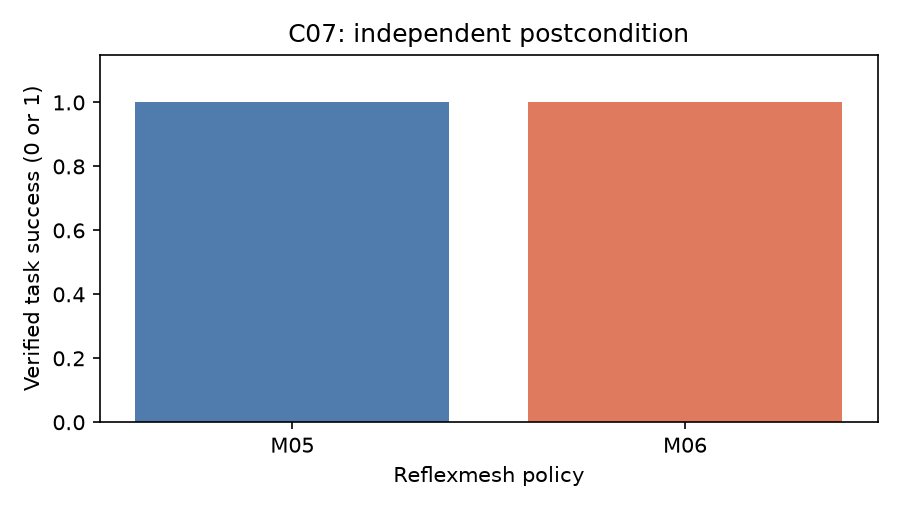

In [8]:
# Plot the independently verified outcomes from the two fresh policy runs.
labels = list(fresh_runs)
success = [fresh_runs[name]["metrics"]["task_success"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, success, color=["#4f7cac", "#e07a5f"])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Verified task success (0 or 1)")
ax.set_xlabel("Reflexmesh policy")
ax.set_title(f"{sample_case}: independent postcondition")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


For level 2 of long-job cancellation on C07, For long-job cancellation, these bars show fresh task-postcondition outcomes for M05 and M06 on C07, with success encoded as 1 and failure as 0. For level 2 of long-job cancellation on C07, Read the case and seed before comparing them. For level 2 of long-job cancellation on C07, This controlled episode illustrates policy behavior but is not a confidence interval and does not establish generalization to other software tasks.


### long-job cancellation · L2 | Recorded controller time

At level 2, the long-job cancellation timing chart uses hash-verified frozen records for M05 and M06 on C07, not machine-dependent timings from fresh episodes. This level 2 long-job cancellation view describes the recorded environment under its declared case, variant and seed.

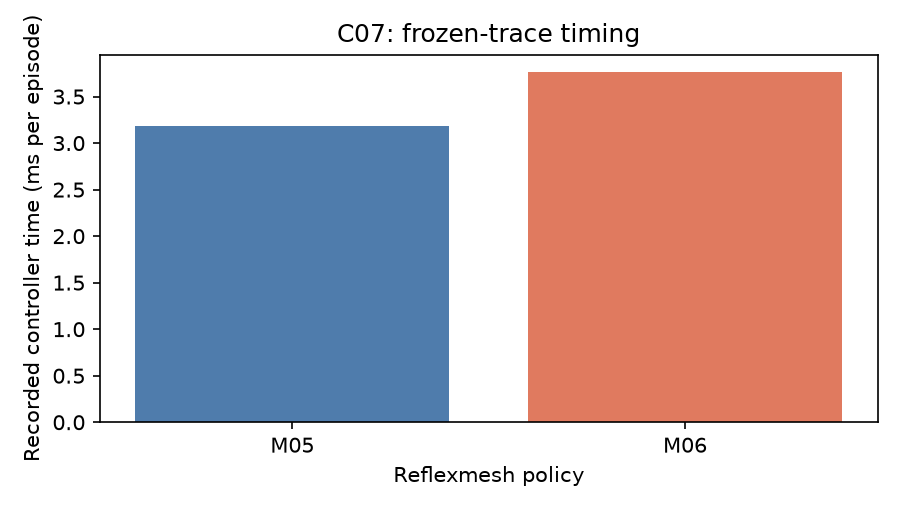

In [9]:
# Plot controller time from the hash-verified frozen records for the matched methods.
labels = list(fresh_runs)
latencies = [records[name]["metrics"]["controller_ms"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, latencies, color=["#4f7cac", "#e07a5f"])
ax.set_ylabel("Recorded controller time (ms per episode)")
ax.set_xlabel("Reflexmesh policy")
ax.set_title(f"{sample_case}: frozen-trace timing")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


The level 2 long-job cancellation chart reads canonical M05/M06 records for C07, nominal variant and seed 40000 after the data boundary verifies their hashes. For this long-job cancellation lesson, the stable figure describes recorded latency and intentionally makes no current-machine speed claim.

## Results

**Answer:** The long-job cancellation comparison executes 2 fresh policy episodes, M05 and M06, under identical C07 conditions; keep the long-job cancellation family and seed strata in view because the frozen matrix contains designed, not population-sampled, tasks.

For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, All 40 M12 failures are in C07, while several methods succeed on all 200 C07 episodes. For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, The result identifies a concrete gap; For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, For level 2 of long-job cancellation on C07, aggregate success alone does not establish whether recurrence, action masking, model error or cancellation timing caused it.


## Summary

For level 2 of long-job cancellation on C07, At level 2, long-job cancellation uses C07 to show how the released method behaves under one declared condition. For level 2 of long-job cancellation on C07, Keep the observed outcome separate from a claim about general software-control intelligence.


## References

- [GRU](https://arxiv.org/abs/1406.1078)
- [PPO](https://arxiv.org/abs/1707.06347)
- [LINUCB](https://arxiv.org/abs/1003.0146)
